<a href="https://colab.research.google.com/github/aidapassela/sp500-rfm-analysis/blob/main/cw1_sp500_rfm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6BUIS017W CRM & CM with BI — Individual Coursework
## Market Analysis and Stock Segmentation Using RFM (S&P 500)

## 0. Setup and parameters

All study parameters are defined **once** here so that every later cell uses the same values.
Package versions and the run date are printed for reproducibility.

In [1]:
!pip install -q --upgrade --force-reinstall yfinance

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-genai 2.12.1 requires websockets<17.0,>=13.0.0, but you have websockets 17.4 which is incompatible.
google-adk 2.7.1 requires websockets<16,>=15.0.1, but you have websockets 17.4 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0

In [2]:
import os, io, json, time, platform, zipfile, datetime as dt, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn
import yfinance as yf
from IPython.display import display

# Study parameters
SEED       = 42
START      = "2021-01-01"                                   # inclusive
END        = "2025-01-01"                                   # EXCLUSIVE
END_INCL   = pd.Timestamp(END) - pd.Timedelta(days=1)       # last calendar day inside the window
BENCH      = "^GSPC"                                        # S&P 500 benchmark
BASE_WIN   = 20      # sessions in the volume baseline (preceding, excluding the tested day)
RFM_WIN    = 60      # latest sessions used for Frequency and Monetary
HV_MULT    = 2.0     # high-volume day: volume > HV_MULT x baseline mean
RUN_DATE   = dt.date.today().isoformat()

np.random.seed(SEED)
for d in ["data", "outputs", "figures"]:
    os.makedirs(d, exist_ok=True)

versions = {
    "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "yfinance": yf.__version__, "matplotlib": plt.matplotlib.__version__, "seaborn": sns.__version__,
    "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
}
print("Run date:", RUN_DATE)
print(json.dumps(versions, indent=2))

# requirements.txt for the GitHub repo
with open("requirements.txt", "w") as f:
    for k, v in versions.items():
        if k != "python":
            f.write(f"{k}=={v}\n")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Run date: 2026-11-22
{
  "python": "3.13.18",
  "pandas": "3.1.1",
  "numpy": "2.4.6",
  "yfinance": "1.8.0",
  "matplotlib": "3.10.0",
  "seaborn": "0.13.2",
  "scipy": "1.16.3",
  "scikit-learn": "1.6.1"
}


In [3]:
print("Verifying upgraded yfinance version and setup...")
import yfinance as yf
print("Upgraded yfinance version successfully imported:", yf.__version__)

Verifying upgraded yfinance version and setup...
Upgraded yfinance version successfully imported: 1.8.0


### 1.1 Ticker selection and data acquisition

##### What the next cells do
1. Read the S&P 500 constituent table from Wikipedia with pandas.read_html and store it with the retrieval date.
2. Download daily Close, Adj Close, Volume for every constituent and for ^GSPC for 2021-01-01 - 2025-01-01 (end exclusive), with auto_adjust= False so both price series are kept.
3. Save compressed raw snapshots plus a metadata file.

In [4]:
# Extract S&P 500 tickers from Wikipedia using Pandas
# User-Agent is required to avoid HTTP 403 blocking from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]
# Replace periods (.) with hyphens (-) in ticker symbols
# This makes symbols such as BRK.B compatible with Yahoo Finance (BRK-B)

print('Total tickers extracted:', len(tickers))

# ADDED: save a dated snapshot of the constituent list (source date requirement) and a sector lookup for Task 3
sp500_df = sp500_df.copy()
sp500_df['Ticker_YF'] = tickers
sp500_df['Retrieval_Date'] = RUN_DATE
sp500_df.to_csv('data/sp500_constituents_snapshot.csv', index=False)
meta = sp500_df.set_index('Ticker_YF')[['Security', 'GICS Sector']]

sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [5]:
print("Number of tables:", len(table))
#Display the column names of each table
for i, df in enumerate(table):
  print(f"Table {i}: {df.columns.tolist()}")

Number of tables: 2
Table 0: ['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry', 'Headquarters Location', 'Date added', 'CIK', 'Founded']
Table 1: ['vteS&P 500 companies', 'vteS&P 500 companies.1']


In [6]:
# Load Daily Market Data via yfinance
# Download daily prices and volume for all S&P 500 tickers
# CHANGED: period is now 01-01-2021 to 01-01-2025 (end exclusive); module used 2022
start = '2021-01-01'
end = '2025-01-01'
END_INCL = pd.Timestamp(end) - pd.Timedelta(days=1)

# ADDED: cache files so the dataset is preserved and re-runs do not re-download
F_ADJ, F_CLOSE, F_VOL, F_MKT = ('data/raw_adj_close.csv.gz', 'data/raw_close.csv.gz',
                                'data/raw_volume.csv.gz', 'data/raw_gspc_adj_close.csv.gz')
FORCE_DOWNLOAD = False
if (not FORCE_DOWNLOAD) and all(os.path.exists(p) for p in [F_ADJ, F_CLOSE, F_VOL, F_MKT]):
    rd = lambda p: pd.read_csv(p, index_col=0, parse_dates=True)
    df, close_df, volume_df = rd(F_ADJ), rd(F_CLOSE), rd(F_VOL)
    market_prices = rd(F_MKT)['^GSPC']
    print('Loaded CACHED snapshots (no download). Retrieval date:', json.load(open('data/download_metadata.json'))['retrieval_date'])
else:
    # CHANGED: keep the whole download (module kept only ['Adj Close'])
    raw = yf.download(tickers, start=start, end=end, auto_adjust=False)
    df = raw['Adj Close']            # same as module
    close_df = raw['Close']          # ADDED
    volume_df = raw['Volume']        # ADDED
    # ADDED: benchmark downloaded here (module did this later, inside the beta cell)
    market_prices = yf.download('^GSPC', start=start, end=end, auto_adjust=False)['Adj Close'].squeeze().rename('^GSPC')
    df.to_csv(F_ADJ, compression='gzip'); close_df.to_csv(F_CLOSE, compression='gzip')
    volume_df.to_csv(F_VOL, compression='gzip'); market_prices.to_frame().to_csv(F_MKT, compression='gzip')
    json.dump({'retrieval_date': RUN_DATE, 'source': 'Yahoo Finance via yfinance', 'yfinance_version': yf.__version__,
               'start': start, 'end_exclusive': end, 'auto_adjust': False}, open('data/download_metadata.json', 'w'), indent=2)
    print('Downloaded and saved snapshots to data/')

# ADDED: make sure every listed ticker has a column (a ticker Yahoo failed to return becomes an all-NaN column)
df, close_df, volume_df = [x.reindex(columns=tickers) for x in (df, close_df, volume_df)]

print('Shape:', df.shape)
df.head()

ERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**                     4%                       ]  20 of 503 completedERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[******************    37%                       ]  186 of 503 completedERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**********************64%******                 ]  320 of 503 completedERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**********************69%********               ]  345 of 503 completedERROR:yfinance:$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'VYLR', 'FDXF', 'Q', 'SNDK']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[*********************100%*********

Downloaded and saved snapshots to data/
Shape: (1005, 503)


Ticker,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,117.366661,48.167671,97.269676,84.219154,232.029343,485.339996,92.300003,18.430204,37.676281,114.009117,...,15.373580,188.764496,228.080002,102.852104,54.757378,93.015907,95.016182,378.130005,141.603363,152.952011
2021-01-05,117.168648,48.480335,98.473206,85.090004,233.350250,485.690002,92.769997,19.048773,37.737343,114.941261,...,15.840141,187.189117,225.360001,106.017517,54.223648,92.903931,95.025169,380.570007,144.053391,154.017914
2021-01-06,118.950966,50.150841,98.268166,84.354950,235.901566,466.309998,90.330002,19.810083,39.194153,118.093239,...,16.444378,188.764496,220.000000,106.652527,55.424553,96.822731,95.545944,394.820007,148.158371,156.280502
2021-01-07,115.898476,50.767231,99.222046,85.257797,238.127335,477.739990,95.160004,19.611834,38.976059,121.235596,...,16.474972,190.200851,226.210007,105.594193,54.340416,101.217422,94.818649,409.100006,147.280060,156.140289
2021-01-08,113.781570,50.168713,99.498398,85.705208,238.995834,485.100006,94.580002,20.159019,38.810329,122.100464,...,16.291401,188.708878,227.649994,104.901451,54.840782,100.191063,96.210403,405.470001,146.956467,157.178101


In [7]:
print(df.columns)

Index(['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A',
       ...
       'WMB', 'WTW', 'WDAY', 'WYNN', 'XEL', 'XYL', 'YUM', 'ZBRA', 'ZBH',
       'ZTS'],
      dtype='str', name='Ticker', length=503)


In [8]:
# Transpose DataFrame: rows = tickers, columns = dates
df1 = df.T

print('Shape after transpose:', df1.shape)
df1

Shape after transpose: (503, 1005)


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
MMM,117.366661,117.168648,118.950966,115.898476,113.781570,112.811867,113.706451,113.549400,113.638138,113.050896,...,123.410522,120.981819,122.523849,124.595955,124.306816,125.636833,126.427109,125.463348,124.451393,124.412834
AOS,48.167671,48.480335,50.150841,50.767231,50.168713,50.829762,52.509205,52.098267,51.294285,50.767231,...,67.828629,66.008636,65.558426,65.826637,65.673370,65.989471,65.989471,65.548843,65.156097,65.338112
ABT,97.269676,98.473206,98.268166,99.222046,99.498398,98.811966,97.029007,99.979790,98.493980,99.621780,...,108.486847,107.184517,107.653732,109.387016,109.463600,109.894531,110.382896,110.114784,108.017632,108.314484
ABBV,84.219154,85.090004,84.354950,85.257797,85.705208,87.103409,87.710625,89.843849,90.231857,89.334633,...,164.530685,162.316711,160.909500,164.718338,167.354507,168.864914,168.114380,166.997986,165.299973,166.707169
ACN,232.029343,233.350250,235.901566,238.127335,238.995834,235.548798,233.784546,233.385071,231.496826,230.271240,...,342.411224,333.125000,356.651978,351.103302,343.819946,346.560791,345.410767,341.337830,337.801636,337.130829
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,93.015907,92.903931,96.822731,101.217422,100.191063,98.922104,98.744827,98.166344,98.464920,96.570816,...,118.026909,114.264351,113.785492,114.479347,114.840958,115.466423,115.779160,114.860504,113.638901,113.384804
YUM,95.016182,95.025169,95.545944,94.818649,96.210403,96.677315,96.677315,96.210403,96.776100,95.734512,...,130.267395,127.105698,126.042145,127.975899,129.426193,130.528412,131.495316,130.750809,129.097458,129.716278
ZBRA,378.130005,380.570007,394.820007,409.100006,405.470001,413.790009,407.950012,412.450012,411.980011,409.220001,...,395.000000,383.470001,385.369995,393.040009,390.649994,395.440002,396.850006,389.070007,383.850006,386.220001


###1.2 Validation and cleaning

**What this section does:**
1. Checks duplicate dates, missing values, non-positive prices, negative/zero volume, large one-day moves and dividend adjustment.
2. Uses the **^GSPC trading calendar** as the reference calendar.
3. Keeps a share **only if it has a complete history** (Close, Adj Close, Volume on every reference date). Nothing is filled.
4. Records every exclusion and its reason in an **inclusion/exclusion log**.
5. Defines the **observation date** (final common completed trading date).


In [9]:
# validation, complete-history rule and exclusion log
print('Before cleaning:', df1.shape)   # number of stocks (rows) and trading dates (columns)

# Calendar checks
print('Duplicate dates (adj/close/volume):', int(df.index.duplicated().sum()),
      int(close_df.index.duplicated().sum()), int(volume_df.index.duplicated().sum()))
ref_cal = market_prices.dropna().index                     # reference trading calendar from ^GSPC
print('Reference trading days:', len(ref_cal), '|', ref_cal.min().date(), '->', ref_cal.max().date())
print('Share dates not in benchmark calendar:', len(df.dropna(how='all').index.difference(ref_cal)))

# Align to the reference calendar (gaps stay NaN - NO filling)
df, close_df, volume_df = [x.reindex(ref_cal) for x in (df, close_df, volume_df)]

LARGE_MOVE = 0.35
chk = pd.DataFrame(index=pd.Index(tickers, name='Ticker'))
chk['n_obs']             = df.notna().sum()
chk['missing_adj']       = df.isna().sum()
chk['missing_close']     = close_df.isna().sum()
chk['missing_vol']       = volume_df.isna().sum()
chk['nonpos_price_days'] = ((df <= 0) | (close_df <= 0)).sum()
chk['neg_volume_days']   = (volume_df < 0).sum()
chk['zero_volume_days']  = (volume_df == 0).sum()
chk['max_abs_close_move'] = close_df.pct_change(fill_method=None).abs().max()
chk['min_adj_to_close']   = (df / close_df).min()          # <1 => dividends adjusted in Adj Close
chk['flag_large_move']    = chk['max_abs_close_move'] > LARGE_MOVE

MANUAL_EXCLUDE = {}    # after inspecting flagged shares, e.g. {'XYZ': 'suspected unadjusted split'}

def build_reasons(r):
    out = []
    if r.n_obs == 0:
        out.append('R1 no data downloaded')
    else:
        if (r.missing_adj + r.missing_close + r.missing_vol) > 0: out.append('R2 missing values / unequal history')
        if r.nonpos_price_days > 0: out.append('R3 non-positive price')
        if r.neg_volume_days > 0:   out.append('R4 negative volume')
        if r.zero_volume_days > 0:  out.append('R5 zero-volume day(s)')
    if r.name in MANUAL_EXCLUDE: out.append('R6 manual review: ' + MANUAL_EXCLUDE[r.name])
    return '; '.join(out)

chk['reasons'] = chk.apply(build_reasons, axis=1)
chk['status']  = np.where(chk['reasons'] == '', 'Retained', 'Excluded')
retained = chk.index[chk.status == 'Retained']

# Keep module variable names: df1 = tickers (rows) x dates (columns), cleaned
df1 = df[retained].T
close_df, volume_df = close_df[retained], volume_df[retained]
assert df1.notna().all().all() and close_df.notna().all().all() and volume_df.notna().all().all()
assert (df1 > 0).all().all() and (close_df > 0).all().all() and (volume_df > 0).all().all()

print('After cleaning:', df1.shape)
print('Rows (tickers) removed:', len(tickers) - df1.shape[0])     # CHANGED: module hardcoded 503

display(chk.loc[chk.status == 'Excluded', 'reasons'].str.split('; ').explode().value_counts().to_frame('n_shares'))
print('Flagged for large one-day Close move (inspect):'); display(chk.loc[chk.flag_large_move, ['max_abs_close_move', 'status']])
print('Shares with dividend-adjusted Adj Close:', int((chk.min_adj_to_close < 0.999).sum()))

# Observation date = final common completed trading date
obs_date = df1.columns.max()
print('OBSERVATION DATE:', obs_date.date())

# Inclusion / exclusion log
log = chk[['status', 'reasons']].join(meta).rename(columns={'status': 'Stage1_Status', 'reasons': 'Stage1_Reasons'})
log.to_csv('outputs/inclusion_exclusion_log_stage1.csv')
df1.head()

Before cleaning: (503, 1005)
Duplicate dates (adj/close/volume): 0 0 0
Reference trading days: 1005 | 2021-01-04 -> 2024-12-31
Share dates not in benchmark calendar: 0
After cleaning: (486, 1005)
Rows (tickers) removed: 17


,n_shares
reasons,
R2 missing values / unequal history,10
R1 no data downloaded,5
R5 zero-volume day(s),2


Flagged for large one-day Close move (inspect):


,max_abs_close_move,status
Ticker,,
APP,0.462652,Excluded
BIIB,0.398503,Retained
BE,0.591867,Retained
CVNA,0.560206,Retained
DXCM,0.406583,Retained
GL,0.531402,Retained
NFLX,0.351166,Retained
RDDT,0.419746,Excluded
HOOD,0.504060,Excluded


Shares with dividend-adjusted Adj Close: 403
OBSERVATION DATE: 2024-12-31


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
MMM,117.366661,117.168648,118.950966,115.898476,113.781570,112.811867,113.706451,113.549400,113.638138,113.050896,...,123.410522,120.981819,122.523849,124.595955,124.306816,125.636833,126.427109,125.463348,124.451393,124.412834
AOS,48.167671,48.480335,50.150841,50.767231,50.168713,50.829762,52.509205,52.098267,51.294285,50.767231,...,67.828629,66.008636,65.558426,65.826637,65.673370,65.989471,65.989471,65.548843,65.156097,65.338112
ABT,97.269676,98.473206,98.268166,99.222046,99.498398,98.811966,97.029007,99.979790,98.493980,99.621780,...,108.486847,107.184517,107.653732,109.387016,109.463600,109.894531,110.382896,110.114784,108.017632,108.314484
ABBV,84.219154,85.090004,84.354950,85.257797,85.705208,87.103409,87.710625,89.843849,90.231857,89.334633,...,164.530685,162.316711,160.909500,164.718338,167.354507,168.864914,168.114380,166.997986,165.299973,166.707169
ACN,232.029343,233.350250,235.901566,238.127335,238.995834,235.548798,233.784546,233.385071,231.496826,230.271240,...,342.411224,333.125000,356.651978,351.103302,343.819946,346.560791,345.410767,341.337830,337.801636,337.130829


In [10]:
# Excluded shares and why
display(log.loc[log.Stage1_Status == 'Excluded', ['Security', 'Stage1_Reasons']])

# Date and context of each flagged share's biggest one-day move
close_all = pd.read_csv('data/raw_close.csv.gz', index_col=0, parse_dates=True)
rows = []
for tk in chk.index[chk.flag_large_move]:
    s = close_all[tk].pct_change(fill_method=None)
    d = s.abs().idxmax(); i = close_all.index.get_loc(d)
    rows.append({'Ticker': tk, 'Date': d.date(), 'Move': round(s[d], 3),
                 'Close_before': close_all[tk].iloc[i-1], 'Close_on': close_all[tk].iloc[i],
                 'Close_5d_later': close_all[tk].iloc[min(i+5, len(close_all)-1)]})
display(pd.DataFrame(rows))

# Zero-volume days in the excluded shares
vol_all = pd.read_csv('data/raw_volume.csv.gz', index_col=0, parse_dates=True)
for tk in chk.index[chk.zero_volume_days > 0]:
    print(tk, [d.date() for d in vol_all.index[vol_all[tk] == 0]])

,Security,Stage1_Reasons
Ticker,,
APP,AppLovin,R2 missing values / unequal history
COIN,Coinbase,R2 missing values / unequal history
CEG,Constellation Energy,R2 missing values / unequal history
EXE,Expand Energy,R2 missing values / unequal history
FDXF,FedEx Freight,R1 no data downloaded
FERG,Ferguson Enterprises,R5 zero-volume day(s)
GEHC,GE HealthCare,R2 missing values / unequal history
GEV,GE Vernova,R2 missing values / unequal history
HONA,Honeywell Aerospace,R1 no data downloaded


,Ticker,Date,Move,Close_before,Close_on,Close_5d_later
0,APP,2024-11-07,0.463,168.550003,246.529999,284.489990
1,BIIB,2022-09-28,0.399,197.789993,276.609985,261.690002
2,BE,2024-11-15,0.592,13.280000,21.139999,25.760000
3,CVNA,2023-06-08,0.560,3.106000,4.846000,5.276000
4,DXCM,2024-07-26,-0.407,107.849998,64.000000,72.300003
5,GL,2024-04-11,-0.531,104.930000,49.169998,65.000000
6,NFLX,2022-04-20,-0.351,34.861000,22.618999,18.854000
7,RDDT,2024-10-30,0.420,81.739998,116.050003,121.080002
8,HOOD,2021-08-04,0.504,46.799999,70.389999,51.189999
9,SMCI,2024-01-19,0.359,31.143999,42.335999,47.415001


FERG [datetime.date(2021, 1, 7), datetime.date(2021, 1, 8), datetime.date(2021, 1, 12), datetime.date(2021, 1, 13), datetime.date(2021, 1, 14), datetime.date(2021, 1, 15), datetime.date(2021, 1, 20), datetime.date(2021, 1, 21), datetime.date(2021, 1, 22), datetime.date(2021, 1, 25), datetime.date(2021, 1, 26), datetime.date(2021, 1, 28), datetime.date(2021, 1, 29), datetime.date(2021, 2, 1), datetime.date(2021, 2, 2), datetime.date(2021, 2, 3), datetime.date(2021, 2, 9), datetime.date(2021, 2, 10), datetime.date(2021, 2, 11), datetime.date(2021, 2, 12), datetime.date(2021, 2, 16), datetime.date(2021, 2, 19), datetime.date(2021, 2, 22), datetime.date(2021, 2, 23), datetime.date(2021, 3, 1), datetime.date(2021, 3, 4), datetime.date(2021, 3, 5)]
SW [datetime.date(2021, 1, 5), datetime.date(2021, 1, 6), datetime.date(2021, 1, 12), datetime.date(2021, 1, 13), datetime.date(2021, 1, 19), datetime.date(2021, 1, 20), datetime.date(2021, 1, 21), datetime.date(2021, 1, 22), datetime.date(2021, 1

In [11]:
vol_all = pd.read_csv('data/raw_volume.csv.gz', index_col=0, parse_dates=True)
for tk in chk.index[chk.zero_volume_days > 0]:
    z = vol_all.index[vol_all[tk] == 0]
    print(tk, '| zero-volume days:', len(z), '| first:', z.min().date(), '| last:', z.max().date())

FERG | zero-volume days: 27 | first: 2021-01-07 | last: 2021-03-05
SW | zero-volume days: 424 | first: 2021-01-05 | last: 2024-07-05


In [12]:
# Corporate-action spot check. Close should show NO ~0.1x/0.05x jump on a split date (it is split-adjusted).
# Dates are well-known split dates
SPLITS = {'AMZN': '2022-06-06', 'GOOGL': '2022-07-18', 'TSLA': '2022-08-25',
          'WMT': '2024-02-26', 'CMG': '2024-06-26', 'NVDA': '2024-06-10', 'AVGO': '2024-07-15'}
rows = []
for tk, d in SPLITS.items():
    if tk in close_df.columns:
        i = close_df.index.searchsorted(pd.Timestamp(d))
        if 0 < i < len(close_df):
            rows.append({'Ticker': tk, 'Date': close_df.index[i].date(),
                         'Close_prev': close_df[tk].iloc[i-1], 'Close_on': close_df[tk].iloc[i],
                         'Close_ratio': close_df[tk].iloc[i] / close_df[tk].iloc[i-1]})
pd.DataFrame(rows)

,Ticker,Date,Close_prev,Close_on,Close_ratio
0,AMZN,2022-06-06,122.349998,124.790001,1.019943
1,GOOGL,2022-07-18,111.777496,109.029999,0.975420
2,TSLA,2022-08-25,297.096680,296.070007,0.996544
3,WMT,2024-02-26,58.520000,59.599998,1.018455
4,CMG,2024-06-26,65.660797,65.860001,1.003034
5,NVDA,2024-06-10,120.888000,121.790001,1.007461
6,AVGO,2024-07-15,170.067001,171.419998,1.007956


### 1.3  Weekly returns and beta

**Weekly returns function :** resamples daily Adj Close to Friday-ending weeks using the last price in each week, then pct_change(fill_method=None) so a missing week cannot become a multi-week "one-week" return.

 Remove incomplete first/last calendar weeks using a calendar rule (keep a week only if its Monday ≥ start date and its Friday ≤ last day of the window). Holiday-shortened weeks are kept.


In [13]:
import pandas as pd

def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy() # making a copy of the transpose dataset
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()
    return weekly_prices.pct_change(fill_method=None)

In [14]:
# All shares weekly returns
weekly_returns = calculate_weekly_returns(df1)

# ADDED: drop incomplete first/last calendar weeks (calendar rule, not hardcoded dates)
labels   = weekly_returns.index
complete = ((labels - pd.Timedelta(days=4)) >= pd.Timestamp(start)) & (labels <= END_INCL)
print('Weekly labels dropped as incomplete:', [d.date() for d in labels[~complete]])
weekly_returns = weekly_returns[complete]
weekly_returns

Weekly labels dropped as incomplete: [datetime.date(2025, 1, 3)]


Ticker,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006422,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085760,0.044729,-0.006690,...,0.056338,0.014781,-0.022359,-0.025681,-0.012166,-0.036133,-0.004946,0.009249,0.007361,-0.038962
2021-01-22,0.021081,0.016364,0.013836,0.003076,0.004416,0.031348,0.051922,-0.018116,-0.001076,0.000951,...,-0.040000,-0.000726,0.058276,0.011485,-0.003079,-0.008696,0.004408,-0.000929,0.005558,0.012522
2021-01-29,0.039162,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026923,-0.048761,...,-0.017130,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052292,-0.051389,-0.045587,-0.055593
2021-02-05,0.019071,0.104972,0.003560,0.060987,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.040509,0.103331,0.160067,0.175424,-0.008595,0.016565,0.037935,0.049713,0.040477,0.032609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29,0.039791,0.014297,0.008577,0.033795,0.010344,0.007381,-0.008457,0.000000,0.014325,0.030858,...,-0.018944,0.024173,-0.066331,0.033848,0.016959,0.001851,0.027131,0.024699,0.017057,-0.009663
2024-12-06,-0.003145,-0.025238,-0.026690,-0.036845,0.000911,0.071773,0.010278,0.000767,-0.058684,0.018917,...,-0.028537,0.001770,0.065723,-0.000106,-0.038864,-0.002998,-0.004629,0.005700,-0.036307,0.006904
2024-12-13,-0.023965,-0.001653,-0.019204,-0.016005,-0.011084,-0.157823,-0.084277,0.022989,-0.025999,-0.011239,...,-0.034256,-0.034659,0.027213,0.001695,-0.023229,-0.045660,-0.004578,-0.013999,-0.011941,0.009747


In [15]:
import pandas as pd
import numpy as np

def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [16]:
market_weekly_returns = market_prices.resample("W-FRI").last().pct_change(fill_method=None)
#pass the first column
market_weekly_returns = pd.DataFrame({"^GSPC": market_weekly_returns.squeeze()})
# Using exactly the same week labels as the shares
market_weekly_returns = market_weekly_returns.reindex(weekly_returns.index)

beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns["^GSPC"]
)

# Mean weekly return (arithmetic) and independent beta check (OLS slope == cov/var)
mean_ret = weekly_returns.mean().rename('Mean_Weekly_Return')
ok = market_weekly_returns['^GSPC'].notna() & weekly_returns.notna().all(axis=1)
ols = pd.Series({s: np.polyfit(market_weekly_returns.loc[ok, '^GSPC'], weekly_returns.loc[ok, s], 1)[0]
                 for s in weekly_returns.columns})
assert np.allclose(ols.values, beta_df['Beta'].values, atol=1e-8), 'beta check failed'
print('OLS-slope check passed for', len(ols), 'shares')
print('Aligned weekly return observations:', int(ok.sum()),
      '| first/last week:', weekly_returns.index[ok].min().date(), '/', weekly_returns.index[ok].max().date())
beta_df.head()

OLS-slope check passed for 486 shares
Aligned weekly return observations: 207 | first/last week: 2021-01-15 / 2024-12-27


,Beta,Paired_weeks
Share,,
MMM,0.869080,207
AOS,1.042804,207
ABT,0.583542,207
ABBV,0.425366,207
ACN,1.143300,207


In [17]:
# Combine into one DataFrame   (module code, unchanged - optional long-format table, not needed for clustering)
combined_df = (
    weekly_returns
    .rename_axis(index="Week", columns="Share")
    .reset_index()
    .melt(
        id_vars="Week",
        var_name="Share",
        value_name="Weekly_Return"
    )
    .join(beta_df[["Beta"]], on="Share")
    .sort_values(["Share", "Week"])
    .reset_index(drop=True)
)

combined_df

,Week,Share,Weekly_Return,Beta
0,2021-01-08,A,NaN,1.074724
1,2021-01-15,A,-0.006690,1.074724
2,2021-01-22,A,0.000951,1.074724
3,2021-01-29,A,-0.048761,1.074724
4,2021-02-05,A,0.025048,1.074724
...,...,...,...,...
101083,2024-11-29,ZTS,-0.009663,0.979782
101084,2024-12-06,ZTS,0.006904,0.979782
101085,2024-12-13,ZTS,0.009747,0.979782
101086,2024-12-20,ZTS,-0.074868,0.979782


In [18]:
# Count null values in each column   (module code, unchanged)
print("Null values per column:")
print(combined_df.isna().sum())

# Remove rows with any null values
rows_before = len(combined_df)
combined_df = combined_df.dropna().reset_index(drop=True)

print("Rows removed:", rows_before - len(combined_df))
print("Rows remaining:", len(combined_df))

Null values per column:
Week               0
Share              0
Weekly_Return    486
Beta               0
dtype: int64
Rows removed: 486
Rows remaining: 100602


### 1.4  Adapted RFM
RFM from **trading volume**:

- **High-volume day:** Volume_t > 2 × mean(Volume over the 20 sessions BEFORE t) (the tested day is excluded from its own baseline; strict >).
- **R:** calendar days from the latest high-volume day to the observation date (no event → missing, **not** 0 → share excluded from RFM).
- **F:** number of high-volume days in the latest **60 trading sessions**.
- **M:** sum of **Close × Volume** over the same 60 sessions (approximate traded value; not market cap or profit).

In [19]:
# 1.4a  High-volume flags
BASE_WIN, RFM_WIN, HV_MULT = 20, 60, 2.0
vol, close = volume_df, close_df   # date x ticker, retained shares only, Close (not Adj Close)

def high_volume_flags(volume, base_win=BASE_WIN, mult=HV_MULT):
    base = volume.shift(1).rolling(base_win, min_periods=base_win).mean()   # previous 20 sessions, EXCLUDING day t
    thr  = mult * base
    flag = (volume > thr) & base.notna()                                    # strict '>'
    return flag, base, thr

hv_flag, base_mean, threshold = high_volume_flags(vol)

# Unit test with the brief's numbers: baseline 1,000,000 -> threshold 2,000,000
test = pd.Series([1_000_000] * 20 + [2_500_000, 1_800_000, 2_000_000, 1_000_000], index=pd.bdate_range('2024-01-01', periods=24))
t_flag, _, _ = high_volume_flags(test)
assert bool(t_flag.iloc[20]) and not bool(t_flag.iloc[21]) and not bool(t_flag.iloc[22])
print('Threshold unit test passed (2.5M qualifies; 1.8M and exactly 2.0M do not)')

sessions = vol.index[vol.index <= obs_date]
win = sessions[-RFM_WIN:]          # latest 60 trading sessions
assert len(win) == RFM_WIN and sessions.get_loc(win[0]) >= BASE_WIN
print('60-session window:', win[0].date(), '->', win[-1].date())
print('Share of share-days flagged high-volume: {:.2%}'.format(hv_flag.values.mean()))

Threshold unit test passed (2.5M qualifies; 1.8M and exactly 2.0M do not)
60-session window: 2024-10-07 -> 2024-12-31
Share of share-days flagged high-volume: 3.74%


In [21]:
# 1.4b  R, F, M and the feature table
last_event = pd.to_datetime(hv_flag.apply(lambda s: s[s].index.max() if s.any() else pd.NaT))
R = (obs_date - last_event).dt.days.rename('R')              # NaN if no event
F = hv_flag.loc[win].sum().rename('F')
daily_value = close * vol                                    # Close x Volume
M = daily_value.loc[win].sum().rename('M')

features = pd.concat([mean_ret, weekly_returns.count().rename('Weekly_Obs'),
                      beta_df['Beta'].rename('Weekly_Beta'), beta_df['Paired_weeks'],
                      R, F, M, last_event.rename('Last_HV_Date')], axis=1)
features.index.name = 'Ticker'
print('No high-volume event (R missing):', int(features.R.isna().sum()),
      '| R = 0:', int((features.R == 0).sum()), '| F = 0:', int((features.F == 0).sum()))
features[['Mean_Weekly_Return', 'Weekly_Beta', 'R', 'F', 'M']].describe().T

No high-volume event (R missing): 0 | R = 0: 0 | F = 0: 10


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,486.0,2.857173e-03,2.651609e-03,-4.468093e-03,1.181531e-03,2.618932e-03,4.207323e-03,1.777248e-02
Weekly_Beta,486.0,9.736953e-01,4.073389e-01,5.545219e-02,6.665993e-01,9.506098e-01,1.179538e+00,3.778560e+00
R,486.0,2.040741e+01,2.134244e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.475000e+01,2.220000e+02
F,486.0,2.989712e+00,1.330800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,486.0,3.940419e+10,1.291388e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847697e+12


In [22]:
#1.4c  Independent brute-force verification (no look-ahead)
def brute_force(ticker):
    v = vol[ticker].to_numpy(); flags = np.zeros(len(v), dtype=bool)
    for i in range(BASE_WIN, len(v)):
        flags[i] = v[i] > HV_MULT * v[i - BASE_WIN:i].mean()
    ev = vol.index[flags]
    r = (obs_date - ev.max()).days if len(ev) else np.nan
    return flags, r, int(flags[-RFM_WIN:].sum()), float((close[ticker].to_numpy()[-RFM_WIN:] * v[-RFM_WIN:]).sum())

rng = np.random.default_rng(42)
sample = rng.choice(features.index, size=min(8, len(features)), replace=False)
for tk in sample:
    flags, r, f, m = brute_force(tk)
    assert (flags == hv_flag[tk].to_numpy()).all()
    assert (np.isnan(r) and np.isnan(features.at[tk, 'R'])) or r == features.at[tk, 'R']
    assert f == features.at[tk, 'F'] and np.isclose(m, features.at[tk, 'M'])
print('Brute-force verification passed for:', list(sample))

Brute-force verification passed for: ['ACGL', 'ODFL', 'TTWO', 'MSI', 'GPC', 'GPN', 'ADM', 'PWR']


In [24]:
# 1.4d  Worked example (use in the report)
cand = [t for t in ['AAPL', 'MSFT'] if t in features.index and not np.isnan(features.at[t, 'R'])]
EXAMPLE = cand[0] if cand else features.dropna(subset=['R']).index[0]
ev_dates = hv_flag.index[hv_flag[EXAMPLE]]; last_ev = ev_dates.max()
print(f'WORKED EXAMPLE: {EXAMPLE}')
print(f'Observation date               : {obs_date.date()}')
print(f'Latest qualifying day          : {last_ev.date()}')
print(f'  Volume that day              : {vol.at[last_ev, EXAMPLE]:,.0f}')
print(f'  Mean of preceding 20 sessions: {base_mean.at[last_ev, EXAMPLE]:,.0f}')
print(f'  Threshold (2 x mean)         : {threshold.at[last_ev, EXAMPLE]:,.0f}')
print(f"R = {obs_date.date()} - {last_ev.date()} = {int(features.at[EXAMPLE, 'R'])} calendar days")
inwin = [d.date() for d in ev_dates if d in win]
print(f'F = qualifying days in 60-session window = {len(inwin)} {inwin}')
print(f"M = sum(Close x Volume) {win[0].date()} -> {win[-1].date()} = ${features.at[EXAMPLE, 'M']:,.0f}")
pd.DataFrame({'Close': close.loc[win, EXAMPLE], 'Volume': vol.loc[win, EXAMPLE], 'Close_x_Volume': daily_value.loc[win, EXAMPLE]}).head(5)

WORKED EXAMPLE: AAPL
Observation date               : 2024-12-31
Latest qualifying day          : 2024-12-20
  Volume that day              : 147,495,300
  Mean of preceding 20 sessions: 45,004,605
  Threshold (2 x mean)         : 90,009,210
R = 2024-12-31 - 2024-12-20 = 11 calendar days
F = qualifying days in 60-session window = 2 [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)]
M = sum(Close x Volume) 2024-10-07 -> 2024-12-31 = $623,303,377,707


,Close,Volume,Close_x_Volume
Date,,,
2024-10-07,221.690002,39505400,8.757952e+09
2024-10-08,225.770004,31855700,7.192062e+09
2024-10-09,229.539993,33591100,7.710501e+09
2024-10-10,229.039993,28183500,6.455149e+09
2024-10-11,227.550003,31759200,7.226806e+09


### 1.5  Final common share set, summaries and saved outputs

The final **common valid share set** = shares with all five features (mean weekly return, beta, R, F, M). It is used for **every** clustering solution in Task 2.

In [25]:
FEATURES = ['Mean_Weekly_Return', 'Weekly_Beta', 'R', 'F', 'M']
log['Stage2_Reason'] = ''
no_event, no_beta = features.index[features.R.isna()], features.index[features.Weekly_Beta.isna()]
log.loc[no_event, 'Stage2_Reason'] = 'R7 no high-volume event in valid history (R missing)'
log.loc[no_beta, 'Stage2_Reason'] = (log.loc[no_beta, 'Stage2_Reason'] + '; R8 beta not estimable').str.strip('; ')
log['Final_Status'] = np.where((log.Stage1_Status == 'Retained') & (log.Stage2_Reason == ''), 'Included', 'Excluded')
log.to_csv('outputs/inclusion_exclusion_log.csv')

final = features.dropna(subset=FEATURES).join(meta)
assert set(final.index) == set(log.index[log.Final_Status == 'Included'])
final.to_csv('outputs/feature_table.csv')

print('Universe:', len(log), '| excluded stage 1:', int((log.Stage1_Status == 'Excluded').sum()),
      '| excluded stage 2:', int(((log.Stage1_Status == 'Retained') & (log.Stage2_Reason != '')).sum()),
      '| FINAL COMMON SHARE SET:', len(final))
display(final[FEATURES].describe().T)
display(pd.DataFrame({'skew': final[FEATURES].skew(),
                      'skew_log1p_M': final[FEATURES].assign(M=np.log1p(final['M'])).skew()}))

Universe: 503 | excluded stage 1: 17 | excluded stage 2: 0 | FINAL COMMON SHARE SET: 486


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,486.0,2.857173e-03,2.651609e-03,-4.468093e-03,1.181531e-03,2.618932e-03,4.207323e-03,1.777248e-02
Weekly_Beta,486.0,9.736953e-01,4.073389e-01,5.545219e-02,6.665993e-01,9.506098e-01,1.179538e+00,3.778560e+00
R,486.0,2.040741e+01,2.134244e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.475000e+01,2.220000e+02
F,486.0,2.989712e+00,1.330800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,486.0,3.940419e+10,1.291388e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847697e+12


,skew,skew_log1p_M
Mean_Weekly_Return,0.867516,0.867516
Weekly_Beta,1.103650,1.103650
R,3.645784,3.645784
F,0.424735,0.424735
M,11.683797,1.079057


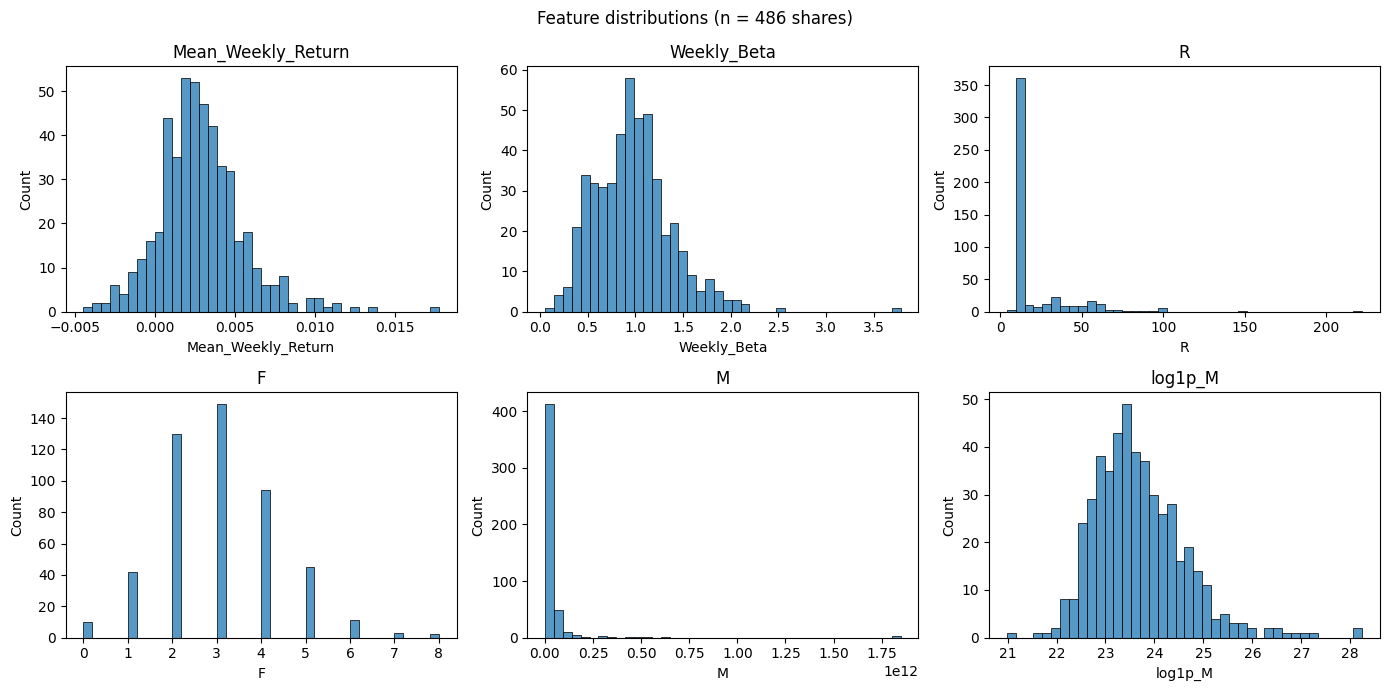

In [26]:
plot_df = final[FEATURES].assign(log1p_M=np.log1p(final['M']))
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), ['Mean_Weekly_Return', 'Weekly_Beta', 'R', 'F', 'M', 'log1p_M']):
    sns.histplot(plot_df[col], bins=40, ax=ax); ax.set_title(col)
plt.suptitle(f'Feature distributions (n = {len(final)} shares)'); plt.tight_layout()
plt.savefig('figures/task1_feature_distributions.png', dpi=150); plt.show()

### Save and push to GitHub
Colab's working folder is deleted when the runtime resets. Run the next cell to download a zip of data/, outputs/, figures/ and requirements.txt, then commit them to your repo.

In [27]:
with zipfile.ZipFile('task1_outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in ['data', 'outputs', 'figures']:
        for root, _, fs in os.walk(folder):
            for fn in fs: z.write(os.path.join(root, fn))
    z.write('requirements.txt')
try:
    from google.colab import files; files.download('task1_outputs.zip')
except Exception as e:
    print('Not in Colab - zip saved in working folder.', e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>